# Figure 4: Reward rate vs. bound

How each participant's bound relates to their reward rate in the three penalty conditions of the
blocked-SNR task (cohort 1, OL; low-SNR blocks 1–3), and how the bound settles over the first 40
trials of each block.

- **A–C** (one panel per block): each subject's **bound plateau** (x; the stopping model's
  `bound_scale`, error bars = 10th–90th percentile of the subject's parametric-bootstrap refits)
  against their reward rate (y). Red: the reward rate of a fixed bound (median, with the 5th–95th
  percentile of 1000 simulated subjects per bound; non-decision time 1 or 2 steps with the
  subjects' mean fitted probabilities); hatched red band: the near-optimal bounds
  (median reward rate ≥ 95% of its maximum; no single optimum is marked because the curves are
  nearly flat near their peak). Black dashed crosshairs: the participants' median bound and reward
  rate. Subjects with a fitted bound beyond the panel are drawn as triangles at the right edge (below
  an axis break if their reward rate is off the scale; their reward rates are printed below, for the caption);
  gray crosses at the edge: plateau at a fit limit, left out of the statistics and the median.
- **D–F** (one panel per block): within-block adaptation. Mean ± SEM across subjects of the
  smoothed, z-scored bound residual over the first 40 trials; gray band: permutation null
  (max-statistic corrected, 95%). Inset: τ of the exponential settle for subjects with a good
  fit (box plot from 5 fits up; points only below that), labeled `n = <good fits>/<subjects with data>`
  and the number of fits at the τ limit (left out).


In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.adaptation import get_adaptation_tau_fits, group_null_band
from pigeon.data import get_data_table, get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import (CM, FS_INSET, CONDITION_LABELS, DATA_COLOR, OPTIMAL_COLOR, add_panel_label, format_p,
                             use_figure_style)
from pigeon.simulation import BLOCK_DEFAULTS, get_simulated_data_table
from pigeon.stopping import get_bound_residuals, get_plateau_at_limit

## Data

- **Bound plateau:** `data/processed/stopping_fits_main.pkl` (`scripts/run_stopping_fits.py`), OL
  raw blocks 1–3 (low SNR). The fits use `get_stopping_model_trials` (trial_number ≥ max(10,
  ceil τ), no DT cutoff, no wall-hit exclusion, raw positions). Error bars: 10th–90th percentile of
  the plateau over the subject's 10 bootstrap refits (`stopping_bootstrap.pkl`,
  `scripts/run_stopping_bootstrap.py`).
- **Plateau at a fit limit** (`get_plateau_at_limit`, 0.002 or 2.0): random responding or
  committing on any movement, i.e. no evidence-based stopping. Left out of every statistic (counts
  printed).
- **Reward rate:** the coins at the end of the block (the last `coin_count`) / 600 steps.


In [2]:
BLOCKS = [1, 2, 3]   # raw OL blocks 1-3: low SNR; no penalty, coin penalty, step penalty
STEPS_PER_BLOCK = BLOCK_DEFAULTS[1]['steps_per_block']
PROCESSED = Path('../data/processed')

data_table_ol = get_data_table(task_type='OL', combine_snr=False)
subjects = np.sort(data_table_ol['subject_index'].dropna().unique())

# Bound plateau per subject x block, its 10th-90th percentile over the bootstrap refits, and which
# subject-blocks sit at a fit limit.
GROUPS = [f'B{b}' for b in BLOCKS]
stopping_fits_ol = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl').query("task == 'OL'")
fit = stopping_fits_ol[stopping_fits_ol['group'].isin(GROUPS)].copy()
fit['at_limit'] = get_plateau_at_limit(fit)
def _grid(df, col):
    return df.pivot(index='subject_index', columns='group', values=col).reindex(index=subjects, columns=GROUPS)
plateau = _grid(fit, 'bound_scale').to_numpy()
at_limit = _grid(fit, 'at_limit').fillna(False).to_numpy(bool)
boot = pd.read_pickle(PROCESSED / 'stopping_bootstrap.pkl').query("task == 'OL' and success")
boot = boot[boot['group'].isin(GROUPS)].groupby(['subject_index', 'group'])['bound_scale_fit']
plateau_lo = boot.quantile(0.1).unstack().reindex(index=subjects, columns=GROUPS).to_numpy()
plateau_hi = boot.quantile(0.9).unstack().reindex(index=subjects, columns=GROUPS).to_numpy()
print('subjects without a fit, by block:', np.isnan(plateau).sum(axis=0))
for bi, block in enumerate(BLOCKS):
    print(f'block {block}: {at_limit[:, bi].sum()} subject(s) with the plateau at a fit limit (left out): '
          f'{list(zip(subjects[at_limit[:, bi]].astype(int), np.round(plateau[at_limit[:, bi], bi], 3)))}')

# Reward rate: coins at the end of each block (coin_count is a running total) per step.
rr = (data_table_ol[data_table_ol['block_index'].isin(BLOCKS)].sort_values('trial_number')
      .groupby(['subject_index', 'block_index'])['coin_count'].last()
      .unstack().reindex(index=subjects, columns=BLOCKS).to_numpy() / STEPS_PER_BLOCK)

# Fixed-bound reward-rate simulations for the figure, at the low SNR of blocks 1-3.
GENERATIVE_STD  = 0.15                                                         # per-step noise SD (OL task)
GENERATIVE_MEAN = float(np.nanmin(np.abs(data_table_ol['snr']))) * GENERATIVE_STD
SIM_BOUNDS      = np.arange(0.01, 0.82, 0.02)   # bound sweep, to the panel edge
NUM_SIM_SUBJ    = 1000                          # simulated subjects per bound (block 3's curve is nearly flat,
                                                # so its peak needs many to be stable)
# NDT of the simulated trials: 1 or 2 steps, with the mean of the subjects' fitted probabilities
_p1 = float(stopping_fits_ol.groupby('subject_index').ndt_p1.first().mean())
NDT_PROBS = (_p1, 1 - _p1)
print(f'GENERATIVE_MEAN={GENERATIVE_MEAN:.4f} (SNR={GENERATIVE_MEAN / GENERATIVE_STD:.3f}); '
      f'P(NDT = 1, 2 steps) = {NDT_PROBS[0]:.3f}, {NDT_PROBS[1]:.3f}')


subjects without a fit, by block: [0 0 1]
block 1: 2 subject(s) with the plateau at a fit limit (left out): [(np.int64(51), np.float64(2.0)), (np.int64(59), np.float64(2.0))]
block 2: 1 subject(s) with the plateau at a fit limit (left out): [(np.int64(51), np.float64(2.0))]
block 3: 3 subject(s) with the plateau at a fit limit (left out): [(np.int64(13), np.float64(0.002)), (np.int64(39), np.float64(1.998)), (np.int64(44), np.float64(0.002))]
GENERATIVE_MEAN=0.0500 (SNR=0.333); P(NDT = 1, 2 steps) = 0.643, 0.357


## Statistics per block

Median [IQR] of the bound plateau across subjects, and the Spearman correlation between bound
plateau and reward rate (subjects with both values; plateau-limit subjects left out).


In [3]:
for bi, block in enumerate(BLOCKS):
    valid = np.isfinite(plateau[:, bi]) & np.isfinite(rr[:, bi]) & ~at_limit[:, bi]
    q25, med, q75 = np.percentile(plateau[valid, bi], [25, 50, 75])
    r, p = scipy.stats.spearmanr(plateau[valid, bi], rr[valid, bi])
    print(f'Block {block}: plateau {med:.3f} [{q25:.3f}, {q75:.3f}]; plateau vs. reward rate '
          f'Spearman r={r:.3f}, {format_p(p)} (n={valid.sum()})')


Block 1: plateau 0.217 [0.110, 0.365]; plateau vs. reward rate Spearman r=-0.583, p<0.001 (n=58)
Block 2: plateau 0.465 [0.306, 0.621]; plateau vs. reward rate Spearman r=0.485, p<0.001 (n=59)
Block 3: plateau 0.311 [0.206, 0.464]; plateau vs. reward rate Spearman r=0.024, p=0.860 (n=56)


## Within-block adaptation (D–F)

Blocks here are the raw blocks 1–3, each a single exposure, so the curves start at the block's
first trial.

**Bound residual** (`pigeon.stopping.get_bound_residuals`). The measured |bound| of a trial (from
`get_bounds`, raw positions) depends on its DT through the bound's within-trial collapse,
overshoot and the congruence-based DT assignment, not only on the subject's bound setting. Each
subject × block is therefore simulated 20 times over its trials from its stopping-model fit, the
simulated trials are run through the same `get_bounds` inference, and the mean measured |bound| at
each DT (DT ≥ 10 pooled) is the expected measured bound. The residual is measured − expected. The
fits exclude each block's adaptation transient, so the expectation is the steady state and
early-trial residuals measure the deviation from it. Trials: DT ≥ 2, no wall hit, RT cutoff, no
trial-number floor (trial number is the x-axis). Subject-blocks whose plateau sits at a fit limit
have no residuals.

**Curves and τ** (`pigeon.adaptation.get_adaptation_tau_fits`). The residual is z-scored per
subject × block and smoothed with a ±3-trial window. 1000 permutations of each subject's trial
order within the block give a subject-specific null; the max-statistic (95th percentile over the 40
trials) of the group-mean null curves is the gray band. τ is fit (`A·exp(−t/τ) + C`) for eligible
subjects: in block 1, those whose curve differs from their null; in blocks 2 and 3, those whose
steady-state measured |bound| differs from the previous block (Mann–Whitney U; the residual is ~0
at steady state in every block by construction, so it cannot show a change between blocks). Fits
at the τ limit (40 trials) are censored and left out.


In [4]:
MAX_TRIAL  = 40                 # trials from the start of the block in the curves (and the tau limit)
RESID_REPS = 20                 # simulated repetitions per trial for the expected measured bound
RESID_SEED = 20261010
ADAPT_COL  = 'bound_residual'

# Bound residuals from the raw (not bias-corrected) bounds; same trials and order as data_table_ol.
raw = get_data_table(task_type='OL', combine_snr=False, correct_bias=None)
assert (raw.index == data_table_ol.index).all()
raw = raw[raw['block_index'].isin(BLOCKS) & raw['choice'].notna()].copy()
raw['condition'] = [f'B{b:.0f}' for b in raw['block_index']]
data_table_ol = data_table_ol.join(
    get_bound_residuals(raw, stopping_fits_ol, num_reps=RESID_REPS, rng=np.random.default_rng(RESID_SEED)))
lim_keys = set(map(tuple, fit.loc[fit['at_limit'], ['subject_index', 'group']].to_numpy()))
l_lim = np.array([(s, f'B{b:.0f}') in lim_keys if np.isfinite(b) else False
                  for s, b in zip(data_table_ol['subject_index'], data_table_ol['block_index'])])
data_table_ol.loc[l_lim, ADAPT_COL] = np.nan
print(f'residuals removed for {l_lim.sum()} trials in {len(lim_keys)} subject-blocks with the plateau at a fit limit')
lg = get_good_trial_array(data_table_ol, min_trial_number=None, block_index=BLOCKS)
print(f'residuals for {data_table_ol.loc[lg, ADAPT_COL].notna().sum()} of {lg.sum()} filtered trials '
      '(the rest: too few simulated trials at their DT)')

tau_fits = get_adaptation_tau_fits(data_table_ol, blocks=BLOCKS, max_trial=MAX_TRIAL, value_col=ADAPT_COL)
trial_nums, curves = tau_fits['trial_nums'], tau_fits['real_curves']
taus, censored = tau_fits['taus'], tau_fits['censored']
n_valid = np.sum(np.isfinite(curves), axis=0)
curve_mean = np.nanmean(curves, axis=0)
curve_sem = np.nanstd(curves, axis=0) / np.sqrt(np.maximum(n_valid, 1))
curve_sem[n_valid < 2] = np.nan
null_thresh = group_null_band(tau_fits['perm_curves'])

for bi, block in enumerate(BLOCKS):
    n_total = np.sum(np.any(np.isfinite(curves[:, :, bi]), axis=1))
    max_abs = np.nanmax(np.abs(curve_mean[:, bi]))
    criterion = ('within-block adaptation' if bi == 0
                 else f'change vs. block {BLOCKS[bi - 1]} (Mann-Whitney U)')
    vt = taus[:, bi][np.isfinite(taus[:, bi]) & ~censored[:, bi]]
    print(f'Block {block}: {tau_fits["sig_within"][:, bi].sum()}/{n_total} subjects with within-block adaptation; '
          f'group curve max |z| {max_abs:.3f} vs. null {null_thresh[bi]:.3f}')
    print(f'  tau-fit eligible ({criterion}): {tau_fits["sig_tau"][:, bi].sum()}/{n_total}; '
          f'{censored[:, bi].sum()} censored at {MAX_TRIAL}; '
          + (f'tau median {np.median(vt):.1f} [{np.percentile(vt, 25):.1f}, {np.percentile(vt, 75):.1f}], '
             f'n={len(vt)}' if len(vt) else 'no uncensored fits'))


residuals removed for 918 trials in 6 subject-blocks with the plateau at a fit limit
residuals for 8786 of 9014 filtered trials (the rest: too few simulated trials at their DT)


Block 1: 6/55 subjects with within-block adaptation; group curve max |z| 0.203 vs. null 0.200
  tau-fit eligible (within-block adaptation): 6/55; 4 censored at 40; tau median 20.4 [11.1, 29.8], n=2
Block 2: 8/56 subjects with within-block adaptation; group curve max |z| 0.341 vs. null 0.192
  tau-fit eligible (change vs. block 1 (Mann-Whitney U)): 40/56; 15 censored at 40; tau median 6.3 [3.4, 16.0], n=24
Block 3: 7/54 subjects with within-block adaptation; group curve max |z| 0.168 vs. null 0.197
  tau-fit eligible (change vs. block 2 (Mann-Whitney U)): 16/54; 6 censored at 40; tau median 4.3 [3.4, 6.4], n=10


## Figure

17.6 cm wide, 2 rows × 3 columns; saves `Figure04.pdf` (+ `.png`) to `FIGURES_DIR`.


Block 1: near-optimal bounds (>=95% of max median RR) 0.01-0.05
Block 1: 2 plateau-limit subject-block(s) drawn as gray crosses: plateaus [2. 2.], reward rates [0.23 0.18]
Block 2: near-optimal bounds (>=95% of max median RR) 0.45-0.63
Block 2: reward rates below the axis break (for the caption): [-0.73 -0.72 -0.38]
Block 2: 3 subject(s) with fitted bound > 0.8 drawn at the edge: bounds [1.07 1.88 0.88], reward rates [-0.05 -0.72 -0.38] (2 below the axis break)
Block 2: 1 plateau-limit subject-block(s) drawn as gray crosses: plateaus [2.], reward rates [-0.73]
Block 3: near-optimal bounds (>=95% of max median RR) 0.23-0.47
Block 3: 1 subject(s) with fitted bound > 0.8 drawn at the edge: bounds [0.91], reward rates [0.03] (0 below the axis break)
Block 3: 3 plateau-limit subject-block(s) drawn as gray crosses: plateaus [0.002 1.998 0.002], reward rates [0.05 0.05 0.02]


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


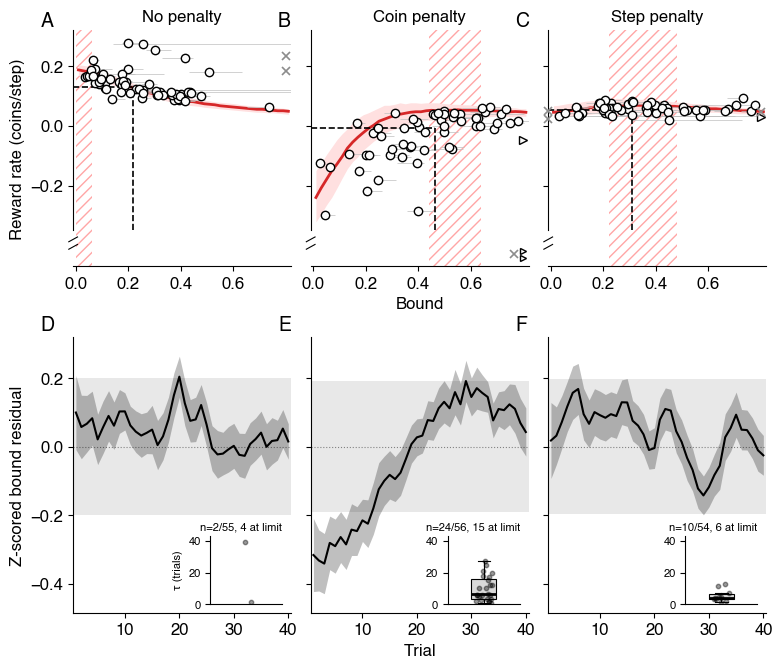

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure04.pdf (+ .png)


In [5]:
WID = 17.6
HTS = [6.0, 7.0]
PSH = 1.8
PSW = 0.5
use_figure_style()

fig_h       = sum(HTS) + PSH
panel_w     = (WID - 2 * PSW) / 3
hspace_frac = PSH / np.mean(HTS)
wspace_frac = PSW / panel_w

fig_comb = plt.figure(figsize=(WID * CM, fig_h * CM))
gs_comb  = gridspec.GridSpec(2, 3, figure=fig_comb,
                              height_ratios=HTS,
                              hspace=hspace_frac, wspace=wspace_frac,
                              left=0, right=1, bottom=0, top=1)
axs_top = [fig_comb.add_subplot(gs_comb[0, c]) for c in range(3)]
axs_bot = [fig_comb.add_subplot(gs_comb[1, c]) for c in range(3)]

gr_c = (0.75, 0.75, 0.75)
wt_c = (0.99, 0.99, 0.99)
rp_c = (1.0,  0.88, 0.88)   # light red: spread of the simulated (optimal-benchmark) reward rates

# ── Pre-compute simulation ribbons for all blocks (single RNG pass) ───────────
# Done up-front so we can determine axis limits before drawing anything.
rng_comb = np.random.default_rng(0)
sbd_all = []
for bi, block in enumerate(BLOCKS):
    sbd = np.full((len(SIM_BOUNDS), 3), np.nan)
    for ss, bnd in enumerate(SIM_BOUNDS):
        sim_table = get_simulated_data_table(
            specs={'num_subjects': NUM_SIM_SUBJ, 'blocks': block},
            generative_mean=GENERATIVE_MEAN,
            bound_mean=bnd,
            ndt_min=1, ndt_max=2, ndt_probs=NDT_PROBS,
            rng=rng_comb,
        )
        sim_coins = sim_table.groupby('subject_index')['coin_count'].last().to_numpy()
        sbd[ss] = np.percentile(sim_coins, [5, 50, 95]) / STEPS_PER_BLOCK
    sbd_all.append(sbd)

# Axis limits (x extends left if the RR peak is at the smallest bound)
all_opt_idx = [int(np.nanargmax(sbd[:, 1])) for sbd in sbd_all]
all_opt_x   = [float(SIM_BOUNDS[i]) for i in all_opt_idx]
all_opt_y   = [float(sbd_all[bi][all_opt_idx[bi], 1]) for bi in range(3)]
x_left      = min(0.0, min(all_opt_x) - 0.02)   # extend left if any optimal is at/near x=0
y_top       = max(max(all_opt_y) * 1.08, 0.32)
# Fitted bounds beyond the wall (0.75) mean commits essentially never come from bound
# crossings (all guesses); such subjects are drawn as triangles at the right edge.
X_SHOW_MAX  = 0.8
TOP_XLIM    = (x_left, X_SHOW_MAX + 0.02)

# y range: down to the lowest reward rate among subjects with an on-scale bound. Below a
# break in the axis, subjects with off-scale bounds and lower reward rates are drawn in a
# row of triangles (their reward rates are printed and noted in the panel).
_rr_all = rr
_on_all = np.isfinite(_rr_all) & (plateau <= X_SHOW_MAX) & ~at_limit
Y_FLOOR     = float(np.floor((np.min(_rr_all[_on_all]) - 0.02) * 20) / 20)   # round down to 0.05
BREAK_Y     = Y_FLOOR - 0.03
BELOW_Y     = Y_FLOOR - 0.08
TOP_YLIM    = (Y_FLOOR - 0.12, y_top)
Y_TICKS     = [t for t in np.round(np.arange(-1.0, 1.0, 0.1), 1) if Y_FLOOR <= t <= y_top and abs(t * 10) % 2 == 0]

# ── Top row: RR vs. bound ─────────────────────────────────────────────────────
# Ideal RR curve is red, matching the ideal-observer curve in Figure02c, as is the
# near-optimal band. The empirical data — participant scatter and its dashed median
# crosshair — are black.
for bi, block in enumerate(BLOCKS):
    ax  = axs_top[bi]
    sbd = sbd_all[bi]

    ax.fill_between(SIM_BOUNDS, np.maximum(sbd[:, 0], Y_FLOOR), np.maximum(sbd[:, 2], Y_FLOOR),
                    color=rp_c, linewidth=0)
    _curve = np.where(sbd[:, 1] >= Y_FLOOR, sbd[:, 1], np.nan)
    ax.plot(SIM_BOUNDS, _curve, '-', color=OPTIMAL_COLOR, linewidth=2)

    # Near-optimal bounds (median RR >= 95% of its maximum) as a hatched red band along the x axis.
    # No single optimum is marked: the curves are nearly flat near their peak (block 3
    # especially), so the best grid point is not stable across simulation runs.
    _near = SIM_BOUNDS[sbd[:, 1] >= 0.95 * np.nanmax(sbd[:, 1])]
    # Hatched, unfilled, so it reads differently from the solid ribbon around the curve.
    ax.axvspan(max(_near.min() - 0.01, TOP_XLIM[0]), _near.max() + 0.01, ymin=0, ymax=1, facecolor='none',
               edgecolor=(1.0, 0.65, 0.65), hatch='///', lw=0, zorder=0)
    print(f'Block {block}: near-optimal bounds (>=95% of max median RR) {_near.min():.2f}-{_near.max():.2f}')

    # Data scatter: one point per subject, horizontal error bars = 10th-90th percentile of the
    # bootstrap refits. Plateau-limit subject-blocks: gray crosses at the axis edge, left out of
    # everything else.
    mean_b   = plateau[:, bi]
    rr_b     = rr[:, bi]
    lim_bi   = np.isfinite(mean_b) & np.isfinite(rr_b) & at_limit[:, bi]
    valid_bi = np.isfinite(mean_b) & np.isfinite(rr_b) & ~at_limit[:, bi]
    xerr     = np.vstack([mean_b - plateau_lo[:, bi], plateau_hi[:, bi] - mean_b])

    on_scale = valid_bi & (mean_b <= X_SHOW_MAX)
    off_scale = valid_bi & (mean_b > X_SHOW_MAX)
    ax.errorbar(mean_b[on_scale], rr_b[on_scale],
                xerr=np.clip(xerr[:, on_scale], 0, None), fmt='none',
                ecolor=gr_c, elinewidth=0.5, capsize=0)
    ax.plot(mean_b[on_scale], rr_b[on_scale], 'ko', markerfacecolor=wt_c, zorder=4)
    in_range = off_scale & (rr_b >= Y_FLOOR)
    below = off_scale & (rr_b < Y_FLOOR)
    ax.plot(np.full(in_range.sum(), X_SHOW_MAX), rr_b[in_range], 'k>', markerfacecolor=wt_c, zorder=4)
    if below.any():
        # Stacked tightly at the right edge so the row fits below the break.
        ys_below = BELOW_Y + 0.022 * (np.arange(below.sum()) - (below.sum() - 1) / 2)
        ax.plot(np.full(below.sum(), X_SHOW_MAX), ys_below, 'k>', markerfacecolor=wt_c, markersize=5,
                zorder=4, clip_on=False)
        _rr_below = rr_b[below | (lim_bi & (rr_b < Y_FLOOR))]
        print(f'Block {block}: reward rates below the axis break (for the caption): {np.sort(np.round(_rr_below, 2))}')
    if off_scale.any():
        print(f'Block {block}: {off_scale.sum()} subject(s) with fitted bound > {X_SHOW_MAX} drawn at the edge: '
              f'bounds {np.round(mean_b[off_scale], 2)}, reward rates {np.round(rr_b[off_scale], 2)}'
              f' ({below.sum()} below the axis break)')
    # Plateau-limit subject-blocks: gray crosses at the edge of the limit they sit at; those with
    # reward rates below the axis break go in the row below it, just left of the triangles.
    _lim_x = np.where(mean_b > X_SHOW_MAX, X_SHOW_MAX, TOP_XLIM[0])
    _lim_y = np.where(rr_b < Y_FLOOR, BELOW_Y, rr_b)
    _lim_x = np.where(rr_b < Y_FLOOR, X_SHOW_MAX - 0.035, _lim_x)
    ax.plot(_lim_x[lim_bi], _lim_y[lim_bi], 'x', color='0.55', markersize=6, mew=1.2, zorder=4, clip_on=False)
    if lim_bi.any():
        print(f'Block {block}: {lim_bi.sum()} plateau-limit subject-block(s) drawn as gray crosses: '
              f'plateaus {np.round(mean_b[lim_bi], 3)}, reward rates {np.round(rr_b[lim_bi], 2)}')
    if (on_scale & (rr_b < Y_FLOOR)).any():
        print(f'WARNING block {block}: on-scale subjects below Y_FLOOR')

    # Black dashed crosshairs for the participant median
    med_x = float(np.nanmedian(mean_b[valid_bi]))
    med_y = float(np.nanmedian(rr_b[valid_bi]))
    ax.plot([med_x, med_x], [Y_FLOOR, med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)
    ax.plot([TOP_XLIM[0], med_x], [med_y, med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)

    ax.set_xlim(*TOP_XLIM)
    ax.set_ylim(*TOP_YLIM)
    ax.set_yticks(Y_TICKS)
    # Axis break: the left spine stops at the floor; a short double slash marks the break,
    # with the off-scale, low-reward-rate subjects (if any) drawn below it.
    ax.spines['left'].set_bounds(Y_FLOOR, TOP_YLIM[1])
    _tr = ax.get_yaxis_transform()
    for dy in (0.0, -0.025):
        ax.plot([-0.02, 0.02], [BREAK_Y + dy - 0.008, BREAK_Y + dy + 0.008], color='k', lw=0.8,
                transform=_tr, clip_on=False)
    if x_left < 0:
        ax.set_xticks([0, 0.2, 0.4, 0.6])   # hide the negative-margin tick
    ax.set_title(CONDITION_LABELS[block])
    if bi == 0:
        ax.set_ylabel('Reward rate (coins/step)')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if bi == 1:
        ax.set_xlabel('Bound')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

# ── Bottom row: within-block learning curves with τ insets ───────────────────
# Curve + ribbon are black (empirical data), consistent with the top row's
# black data crosshairs. The permutation null band is a light gray, chosen to
# stay visually distinct from the black curve/ribbon (which render as a
# mid-gray at alpha=0.25) rather than blending into it.
_NULL_COLOR  = (0.85, 0.85, 0.85)
_CURVE_COLOR = 'k'

_top_lo  = min(np.nanmin(curve_mean - curve_sem), -np.max(null_thresh))
_top_hi  = max(np.nanmax(curve_mean + curve_sem),  np.max(null_thresh))
_top_pad = 0.08 * (_top_hi - _top_lo)
_CURVE_YLIM = (_top_lo - _top_pad, _top_hi + _top_pad)

_rng_jit = np.random.default_rng(42)

for bi, block in enumerate(BLOCKS):
    ax = axs_bot[bi]
    mn  = curve_mean[:, bi]
    sem = curve_sem[:, bi]
    ok  = np.isfinite(mn) & np.isfinite(sem)
    thr = null_thresh[bi]

    ax.axhline(0, color='k', linestyle=':', linewidth=0.8, zorder=0)
    ax.axhspan(-thr, thr, color=_NULL_COLOR, alpha=0.6, linewidth=0, zorder=0)
    ax.fill_between(trial_nums[ok], mn[ok] - sem[ok], mn[ok] + sem[ok],
                    alpha=0.25, color=_CURVE_COLOR, linewidth=0)
    ax.plot(trial_nums[ok], mn[ok], '-', color=_CURVE_COLOR, linewidth=1.5)

    ax.set_xlim(0.5, MAX_TRIAL + 0.5)
    ax.set_ylim(*_CURVE_YLIM)
    if bi == 0:
        ax.set_ylabel('Z-scored bound residual')
    else:
        ax.tick_params(axis='y', labelleft=False)
    if bi == 1:
        ax.set_xlabel('Trial')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

    # ── τ inset (lower-right corner of the learning-curve panel) ──────────────
    ax_ins = ax.inset_axes([0.63, 0.03, 0.33, 0.25])

    is_cens = censored[:, bi]
    vt      = taus[:, bi][np.isfinite(taus[:, bi]) & ~is_cens]
    n_total = int(np.sum(np.any(np.isfinite(curves[:, :, bi]), axis=1)))

    if len(vt) >= 5:
        ax_ins.boxplot(vt, positions=[1], widths=0.35,
                       patch_artist=True,
                       medianprops=dict(color='k', linewidth=2),
                       boxprops=dict(facecolor=(0.85, 0.85, 0.85), linewidth=0.8),
                       whiskerprops=dict(linewidth=0.8),
                       capprops=dict(linewidth=0.8),
                       flierprops=dict(marker='none'))
    if len(vt):
        jit = _rng_jit.uniform(-0.12, 0.12, len(vt))
        ax_ins.scatter(np.ones(len(vt)) + jit, vt, s=10, color='k', alpha=0.4, zorder=4)
    else:
        ax_ins.text(1, MAX_TRIAL / 2, 'no fits', ha='center', va='center', fontsize=FS_INSET)

    # n label above the inset: fit subjects (successful, non-censored) over the
    # total number of subjects with usable data in this block, and the fits at the tau limit.
    n_cens = int(is_cens.sum())
    ax_ins.text(1.0, 1.05, f'n={len(vt)}/{n_total}' + (f', {n_cens} at limit' if n_cens else ''),
                transform=ax_ins.transAxes, ha='right', va='bottom', fontsize=FS_INSET)

    ax_ins.set_xlim(0.5, 1.5)
    ax_ins.set_ylim(0, MAX_TRIAL * 1.08)
    ax_ins.set_xticks([])
    if bi == 0:
        ax_ins.set_ylabel('τ (trials)', fontsize=FS_INSET)
    ax_ins.tick_params(labelsize=FS_INSET)
    for sp in ['top', 'right']:
        ax_ins.spines[sp].set_visible(False)

for bi in range(3):
    add_panel_label(axs_top[bi], chr(65 + bi))
    add_panel_label(axs_bot[bi], chr(68 + bi))

out_comb = FIGURES_DIR / 'Figure04.pdf'
fig_comb.savefig(out_comb, dpi=300, bbox_inches='tight')
fig_comb.savefig(out_comb.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out_comb} (+ .png)')

